# Nhiệm vụ 7 — Đánh giá chất lượng PCA + K-Means V2

Đánh giá đúng 60 development snapshots từ 2019-01-31 đến 2023-12-29, Global K=2.
Nguồn số liệu duy nhất là diagnostics.csv của m2-task6-pca-kmeans-v2.
Manifest Nhiệm vụ 6 chỉ dùng kiểm tra tính toàn vẹn và quy tắc đã đóng băng.
Không import backend, không tính lại khoảng cách, không fit scaler/PCA/K-Means,
không mở dữ liệu holdout và không sử dụng chỉ số danh mục.

Thực hiện workflow 5 bước của phần Nhiệm vụ 7 trong kế hoạch M2:
đọc diagnostics → thống kê K=2 → hai bảng chuẩn → năm biểu đồ → biện luận A/B/C.
Bộ cũ 15 tháng được giữ nguyên; kết quả mới nằm trong m2-evaluation-pca-kmeans-v2.
Chọn kernel Python 3.11 hoặc mới hơn, rồi Run All. Chạy lại cùng nguồn sẽ kiểm chứng
nội dung đã có; thay đổi nguồn hoặc nội dung cần tạo phiên bản mới.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import math
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

CWD = Path.cwd().resolve()
ROOT = next((p for p in [CWD, *CWD.parents]
             if (p / 'configs/experiments/m2_market_only_v2.json').is_file()), None)
if ROOT is None:
    ROOT = next((p for p in CWD.iterdir()
                 if p.is_dir() and (p / 'configs/experiments/m2_market_only_v2.json').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở workspace M2_v1, repository hoặc M2/notebooks.')
TASK_DIR = ROOT / 'M2/artifacts/m2-task6-pca-kmeans-v2'
EVAL_DIR = ROOT / 'M2/artifacts/m2-evaluation-pca-kmeans-v2'
REPORT_PATH = ROOT / 'M2/reports/Bao_cao_M2_Nhiem_vu_7_Chat_luong_cum_PCA_KMeans_v2.md'
DIAG_PATH = TASK_DIR / 'diagnostics.csv'
MANIFEST_PATH = TASK_DIR / 'manifest.json'
METRICS = ['silhouette', 'davies_bouldin', 'calinski_harabasz', 'inertia', 'cluster_balance']
SUMMARY_COLUMNS = ['metric', 'n_total', 'n_available', 'mean', 'median', 'minimum', 'maximum']

def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def immutable_bytes(path, data):
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open('wb') as stream:
        stream.write(data)

def markdown_table(frame):
    def clean(value):
        return str(value).replace('|', r'\|').replace('\n', ' ')
    lines = ['| ' + ' | '.join(map(clean, frame.columns)) + ' |',
             '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |']
    lines += ['| ' + ' | '.join(map(clean, row)) + ' |'
              for row in frame.itertuples(index=False, name=None)]
    return '\n'.join(lines)

source_manifest = json.loads(MANIFEST_PATH.read_text(encoding='utf-8'))
assert source_manifest['status'] == 'complete'
assert source_manifest['task6_exports_complete'] is True
assert source_manifest['artifact_id'] == 'm2-task6-pca-kmeans-v2'
assert source_manifest['n_snapshots'] == 60
CONFIG = source_manifest['config']
DEV_DATES = CONFIG['development_snapshots']
assert CONFIG['protocol_scope'] == 'm2_market_only_v2'
assert len(DEV_DATES) == len(set(DEV_DATES)) == 60
assert DEV_DATES[0] == '2019-01-31' and DEV_DATES[-1] == '2023-12-29'
assert CONFIG['clustering']['algorithm'] == 'pca_kmeans' and CONFIG['clustering']['k'] == 2
assert CONFIG['portfolio_evaluation']['enabled'] is False
N_COMPONENTS = CONFIG['clustering']['pca']['n_components']
SOURCE_HASH, SOURCE_MANIFEST_HASH = sha(DIAG_PATH), sha(MANIFEST_PATH)
assert SOURCE_HASH == source_manifest['artifacts']['diagnostics.csv']
print('Nguồn:', DIAG_PATH)
print('Development:', DEV_DATES[0], '→', DEV_DATES[-1], '| K=2 | PCA:', N_COMPONENTS)


Nguồn: C:\Users\HP\Downloads\Phân cụm động lượng TTCK\M2\artifacts\m2-task6-pca-kmeans-v2\diagnostics.csv
Development: 2019-01-31 → 2023-12-29 | K=2 | PCA: 2


## Bước 1 — Kiểm tra diagnostics và trích đúng K=2

Kiểm tra schema, 420 dòng (60 tháng × 7 K), khóa duy nhất, đúng ngày và hội tụ.
Chỉ 60 dòng K=2 được dùng cho mọi thống kê và biểu đồ. Cluster sizes là dữ liệu
chẩn đoán đã lưu, dùng để phân biệt Balance=min/max với tỷ trọng cụm nhỏ=min/N.


In [2]:
diagnostics = pd.read_csv(DIAG_PATH)
required = ['snapshot_date', 'k', *METRICS, 'cluster_sizes', 'converged']
assert set(required).issubset(diagnostics.columns)
assert not diagnostics.duplicated(['snapshot_date', 'k']).any()
expected_keys = {(day, k) for day in DEV_DATES for k in CONFIG['clustering']['k_range']}
assert len(diagnostics) == 420
assert set(zip(diagnostics.snapshot_date, diagnostics.k)) == expected_keys
df_k2 = diagnostics[diagnostics.k.eq(2)].sort_values('snapshot_date').reset_index(drop=True)
assert df_k2.snapshot_date.tolist() == DEV_DATES and len(df_k2) == 60
for metric in METRICS:
    df_k2[metric] = pd.to_numeric(df_k2[metric], errors='raise')
    assert df_k2[metric].map(math.isfinite).all(), metric
assert df_k2.converged.astype(str).str.lower().eq('true').all()
sizes = df_k2.cluster_sizes.map(json.loads)
assert all(set(s) == {'0', '1'} and all(type(v) is int and v > 0 for v in s.values()) for s in sizes)
counts = pd.DataFrame({
    'snapshot_date': df_k2.snapshot_date,
    'n_eligible': sizes.map(lambda s: sum(s.values())),
    'min_size': sizes.map(lambda s: min(s.values())),
    'max_size': sizes.map(lambda s: max(s.values())),
})
counts['pct_small'] = counts.min_size / counts.n_eligible
assert counts.n_eligible.ge(CONFIG['min_eligible_count']).all()
assert int(counts.n_eligible.sum()) == source_manifest['n_assignments']
assert all(math.isclose(b, small / large, rel_tol=1e-12, abs_tol=1e-12)
           for b, small, large in zip(df_k2.cluster_balance, counts.min_size, counts.max_size))
assert df_k2.silhouette.between(-1, 1).all()
assert df_k2.cluster_balance.between(0, 1, inclusive='right').all()
assert df_k2[['davies_bouldin', 'calinski_harabasz', 'inertia']].ge(0).all().all()
print('PASS: 420 dòng; K=2 có đủ 60 tháng, hữu hạn, hội tụ; không trùng khóa.')


PASS: 420 dòng; K=2 có đủ 60 tháng, hữu hạn, hội tụ; không trùng khóa.


## Bước 2–3 — Hai bảng chuẩn

Bảng 1 gồm đúng 5 dòng × 7 cột; n_total=n_available=60.
Bảng 2 gồm đúng 60 dòng × 6 cột, hiển thị đầy đủ bằng HTML trong notebook.
Chỉ Bảng 1 được xuất thành CSV; giữ đầy đủ độ chính xác, không làm tròn file số liệu.


In [3]:
summary_df = pd.DataFrame([
    dict(metric=m, n_total=60, n_available=int(df_k2[m].notna().sum()),
         mean=df_k2[m].mean(), median=df_k2[m].median(),
         minimum=df_k2[m].min(), maximum=df_k2[m].max())
    for m in METRICS
], columns=SUMMARY_COLUMNS)
assert summary_df.shape == (5, 7) and summary_df.columns.tolist() == SUMMARY_COLUMNS
assert summary_df.metric.tolist() == METRICS
assert summary_df.n_total.eq(60).all() and summary_df.n_available.eq(60).all()
detail_df = df_k2[['snapshot_date', *METRICS]].rename(columns=dict(zip(
    ['snapshot_date', *METRICS], ['Snapshot', 'Silhouette', 'DB', 'CH', 'Inertia', 'Balance'])))
assert detail_df.shape == (60, 6)
with pd.option_context('display.max_rows', 60, 'display.max_columns', 7, 'display.precision', 6):
    display(summary_df)
    display(detail_df)
immutable_bytes(EVAL_DIR / 'quality_summary.csv',
                summary_df.to_csv(index=False, lineterminator='\n').encode('utf-8'))


,metric,n_total,n_available,mean,median,minimum,maximum
0,silhouette,60,60,0.946822,0.946855,0.903889,9.813416e-01
1,davies_bouldin,60,60,0.392388,0.397056,0.203106,5.024637e-01
2,calinski_harabasz,60,60,1750.124284,1631.466715,679.358341,3.823662e+03
3,inertia,60,60,848455.026434,372878.404927,56117.361311,3.969503e+06
4,cluster_balance,60,60,0.020535,0.020684,0.003252,5.079365e-02


,Snapshot,Silhouette,DB,CH,Inertia,Balance
0,2019-01-31,0.946776,0.315575,2305.684046,1.070607e+05,0.018634
1,2019-02-28,0.939040,0.452440,1583.082311,1.941385e+05,0.023401
2,2019-03-29,0.903889,0.470727,1507.588679,5.918765e+04,0.050794
3,2019-04-26,0.914797,0.445497,1196.109156,8.506376e+04,0.026074
4,2019-05-31,0.928886,0.455470,802.254096,2.016776e+05,0.022556
5,2019-06-28,0.938682,0.369276,1960.429966,1.280160e+05,0.022059
6,2019-07-31,0.930036,0.457128,1398.695609,1.660624e+05,0.027656
7,2019-08-30,0.928143,0.502464,1380.344654,1.619926e+05,0.024226
8,2019-09-30,0.919389,0.460047,1633.274143,1.862785e+05,0.031704
9,2019-10-31,0.920277,0.491523,1136.799833,2.265914e+05,0.033512


## Bước 4 — Năm biểu đồ chất lượng

Vẽ đủ 60 điểm theo thời gian; chọn 15 nhãn ngày để trục hoành đọc được.
Mỗi đồ thị 10 × 3,8 inch, xoay nhãn 45°, lưới alpha=0,5, median đỏ nét đứt.
Balance bổ sung đường đỏ đậm nét chấm tại 0,05. Inertia luôn kèm lưu ý về N
và độ phân tán: không dùng giá trị tuyệt đối để xếp hạng chất lượng giữa các tháng.


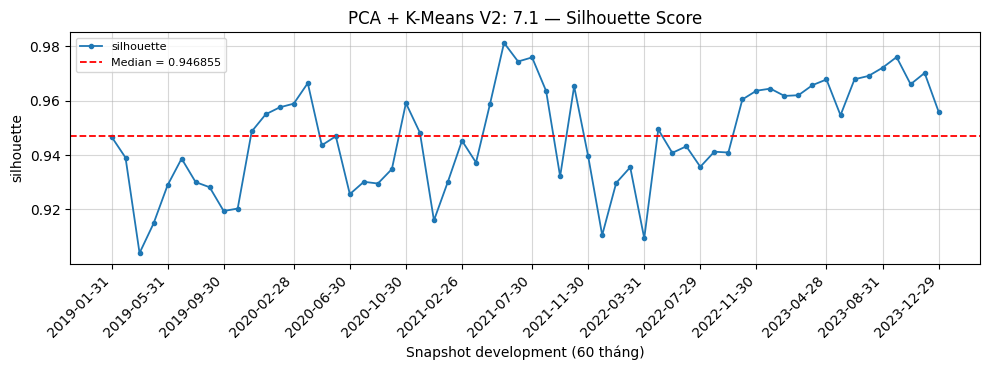

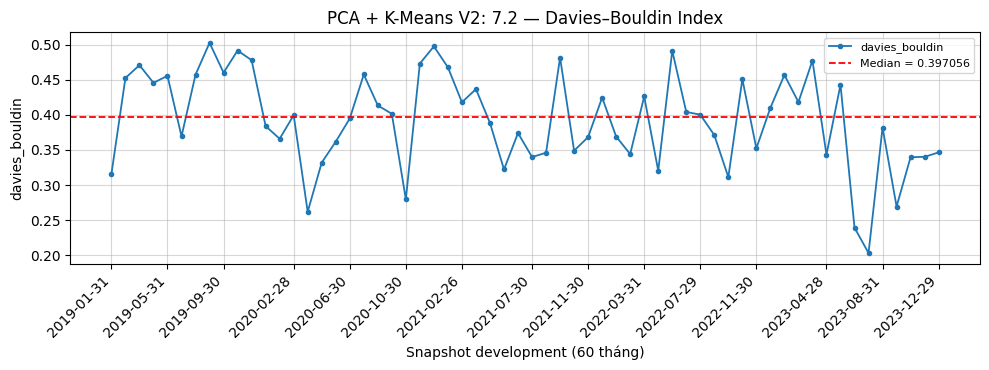

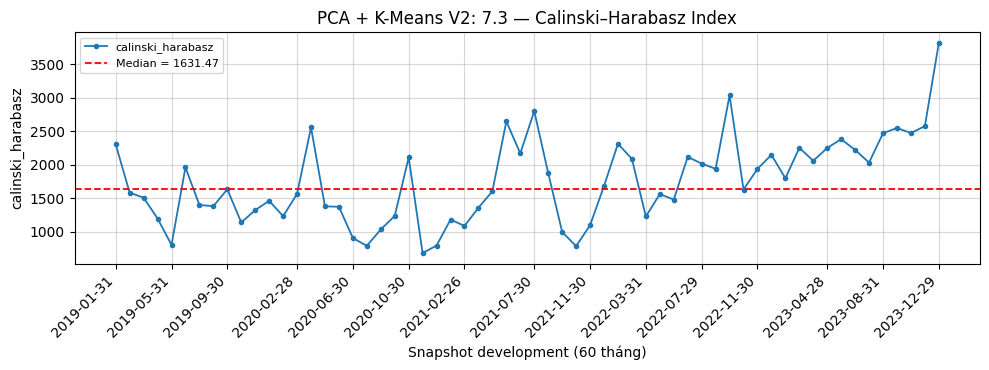

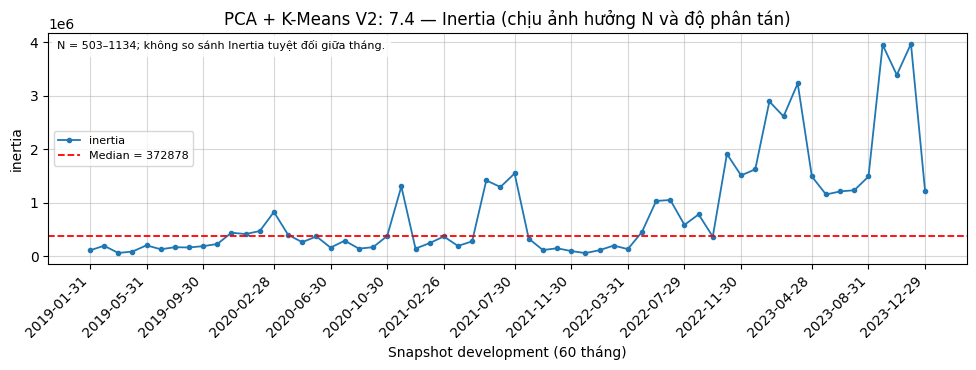

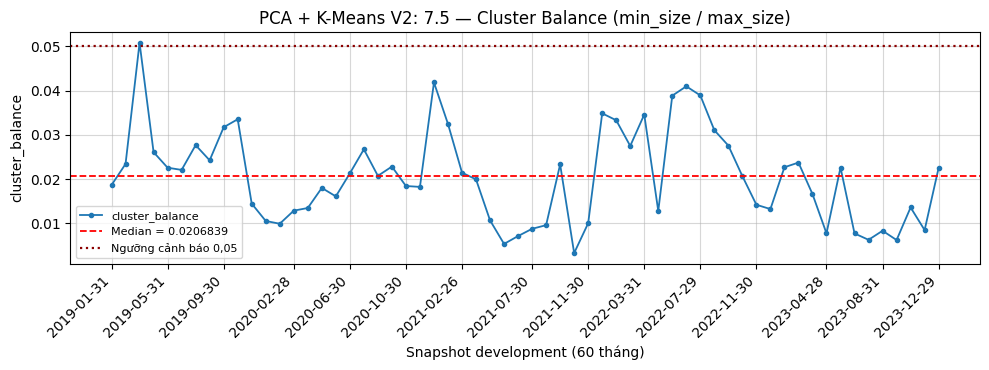

In [4]:
from io import BytesIO

titles = [
    '7.1 — Silhouette Score',
    '7.2 — Davies–Bouldin Index',
    '7.3 — Calinski–Harabasz Index',
    '7.4 — Inertia (chịu ảnh hưởng N và độ phân tán)',
    '7.5 — Cluster Balance (min_size / max_size)',
]
FIGURE_PATHS = []
ticks = sorted(set(round(i * (len(df_k2) - 1) / 14) for i in range(15)))
for index, (metric, title) in enumerate(zip(METRICS, titles), 1):
    fig, ax = plt.subplots(figsize=(10, 3.8))
    ax.plot(range(60), df_k2[metric], marker='o', markersize=3, linewidth=1.3, label=metric)
    median_value = float(df_k2[metric].median())
    ax.axhline(median_value, color='red', linestyle='--', linewidth=1.3,
               label=f'Median = {median_value:.6g}')
    if metric == 'cluster_balance':
        ax.axhline(0.05, color='darkred', linestyle=':', linewidth=1.6, label='Ngưỡng cảnh báo 0,05')
    if metric == 'inertia':
        ax.text(0.01, 0.97,
                f'N = {counts.n_eligible.min()}–{counts.n_eligible.max()}; không so sánh Inertia tuyệt đối giữa tháng.',
                transform=ax.transAxes, va='top', fontsize=8,
                bbox=dict(facecolor='white', alpha=0.85, edgecolor='none'))
    ax.set_xticks(ticks, [DEV_DATES[i] for i in ticks], rotation=45, ha='right')
    ax.set(title='PCA + K-Means V2: ' + title, xlabel='Snapshot development (60 tháng)', ylabel=metric)
    ax.grid(alpha=0.5)
    ax.legend(loc='best', fontsize=8)
    fig.tight_layout()
    image_buffer = BytesIO()
    fig.savefig(image_buffer, format='png', dpi=160)
    path = EVAL_DIR / 'figures' / f'07_{index}_{metric}.png'
    immutable_bytes(path, image_buffer.getvalue())
    FIGURE_PATHS.append(path)
    plt.show()
    plt.close(fig)
assert len(FIGURE_PATHS) == 5


## Bước 5 — Biện luận theo bằng chứng

Áp dụng rubric Balance dưới 0,10 hoặc tỷ trọng cụm nhỏ dưới 10% để nhận diện
phân cụm bất đối xứng/cô lập nhóm ngoại lai. Ngưỡng 0,05 của biểu đồ là cảnh báo riêng,
không đồng nhất Balance=min/max với pct_small=min/N.
Nguyên nhân như đuôi dày, đầu cơ hay tập trung dòng tiền chỉ là cách diễn giải có điều kiện:
diagnostics không cung cấp danh tính mã, hồ sơ 8 feature hoặc bằng chứng nhân quả.
Không gắn biến động chỉ số với một sự kiện thị trường cụ thể khi chưa có nguồn chứng minh.


In [5]:
med = summary_df.set_index('metric')['median']
balance_005 = int(df_k2.cluster_balance.lt(0.05).sum())
asymmetric = df_k2.cluster_balance.lt(0.10) | counts.pct_small.lt(0.10)
singleton_dates = counts.loc[counts.min_size.eq(1), 'snapshot_date'].tolist()
singletons_text = ', '.join(singleton_dates) if singleton_dates else 'không có'
sil_min = df_k2.loc[df_k2.silhouette.idxmin()]
sil_max = df_k2.loc[df_k2.silhouette.idxmax()]
db_min = df_k2.loc[df_k2.davies_bouldin.idxmin()]
db_counts = counts[counts.snapshot_date.eq(db_min.snapshot_date)].iloc[0]
inertia_min = df_k2.loc[df_k2.inertia.idxmin()]
inertia_max = df_k2.loc[df_k2.inertia.idxmax()]
synthesis = f'''## A — Phán quyết kỹ thuật

Median Silhouette = {med.silhouette:.6f}; cả {int(df_k2.silhouette.gt(0.70).sum())}/60
tháng vượt 0,70 theo rubric mô tả của kế hoạch. Thấp nhất
{sil_min.silhouette:.6f} tại {sil_min.snapshot_date}, cao nhất
{sil_max.silhouette:.6f} tại {sil_max.snapshot_date}. Median Davies–Bouldin =
{med.davies_bouldin:.6f}; median Calinski–Harabasz = {med.calinski_harabasz:.6f}.
Các chỉ số cho thấy phân tách hình học rõ trong không gian PCA {N_COMPONENTS} chiều.

Điểm yếu là mất cân bằng: median Balance = {med.cluster_balance:.6f};
{balance_005}/60 tháng Balance < 0,05; {int(asymmetric.sum())}/60 tháng
đáp ứng rubric bất đối xứng. Median tỷ trọng cụm nhỏ = {counts.pct_small.median():.4%},
khác với Balance. Có {len(singleton_dates)} tháng cụm nhỏ chỉ 1 mã: {singletons_text}.
DB thấp nhất {db_min.davies_bouldin:.6f} tại {db_min.snapshot_date} đi cùng cụm
{int(db_counts.min_size)}/{int(db_counts.max_size)} mã: metric đẹp không loại bỏ
cảnh báo về cụm cực nhỏ.

Median Inertia = {med.inertia:.6f}; khoảng
{inertia_min.inertia:.6f} ({inertia_min.snapshot_date}) đến
{inertia_max.inertia:.6f} ({inertia_max.snapshot_date}). N thay đổi
{counts.n_eligible.min()}–{counts.n_eligible.max()} mã, nên không xếp hạng
tháng bằng Inertia tuyệt đối; giá trị này còn phụ thuộc độ phân tán và quy mô mẫu.
Biến thiên 5 chỉ số là biến thiên chất lượng từng tháng, chưa phải bằng chứng
ổn định nhãn hay hành vi chuyển cụm.

## B — Bản chất cấu trúc thị trường và giới hạn suy luận

Theo ngưỡng đã nêu, cấu trúc quan sát là **phân cụm bất đối xứng / cô lập nhóm ngoại lai
(Asymmetric Outlier Isolation)**: phần lớn quan sát thuộc một cụm, một nhóm nhỏ
được tách ra. Không có tháng nào đạt Balance ≥ 0,30
({int(df_k2.cluster_balance.ge(0.30).sum())}/60), do đó không diễn giải đây là hai
chế độ thị trường cân bằng.

Trong bối cảnh cổ phiếu Việt Nam, phân phối đuôi dày, một số mã có động lượng,
rủi ro hoặc thanh khoản cực đoan và dòng tiền tập trung là các cơ chế có thể
phù hợp với hình học này. Protocol giữ outlier, không clipping/winsorization,
nên các quan sát cực đoan vẫn có thể ảnh hưởng khoảng cách và tâm cụm.
Tuy nhiên diagnostics.csv chỉ chứa kết quả hình học: chưa đủ để xác nhận
đầu cơ, dòng tiền hay feature cụ thể là nguyên nhân. Nhiệm vụ 8 cần kiểm tra hồ sơ
trên 8 feature gốc trước khi gắn nhãn kinh tế. Silhouette cao trong trường hợp
cụm rất nhỏ phản ánh sự tách biệt, không chứng minh cấu trúc cân bằng hoặc lợi ích đầu tư.

## C — Bàn giao Nhiệm vụ 10

Bộ PCA + K-Means V2 đủ dữ liệu chất lượng hình học để tham gia đối chiếu:
60/60 tháng, 5/5 chỉ số hữu hạn, K=2 hội tụ, hai bảng chuẩn và năm biểu đồ.
Đây là kết luận về khả năng bàn giao bằng chứng, không phải tuyên bố mô hình chiến thắng.
Khi so sánh, dùng median Silhouette làm chỉ số chính, DB làm đối chiếu/phá hòa,
CH và Balance làm kiểm tra bổ sung; phải giữ rõ cảnh báo {balance_005}/60 tháng
Balance < 0,05 và {len(singleton_dates)} singleton.

Các phương án đối chứng phải cùng dữ liệu, universe, 60 development snapshots
2019–2023 và cách đo phù hợp với không gian phân cụm. Không đối chiếu trực tiếp
với bảng PCA cũ 15 tháng hoặc suy PCA cải thiện độ ổn định khi Nhiệm vụ 9 chưa làm.
Nhiệm vụ 8–9 và đối đầu ở Nhiệm vụ 10 chưa được thực hiện trong lần đánh giá này.
Không chọn lại K/PCA, không fit lại mô hình, không dùng holdout hoặc Return/Sharpe/ROI.
'''
display(Markdown(synthesis))


## A — Phán quyết kỹ thuật

Median Silhouette = 0.946855; cả 60/60
tháng vượt 0,70 theo rubric mô tả của kế hoạch. Thấp nhất
0.903889 tại 2019-03-29, cao nhất
0.981342 tại 2021-05-31. Median Davies–Bouldin =
0.397056; median Calinski–Harabasz = 1631.466715.
Các chỉ số cho thấy phân tách hình học rõ trong không gian PCA 2 chiều.

Điểm yếu là mất cân bằng: median Balance = 0.020684;
59/60 tháng Balance < 0,05; 60/60 tháng
đáp ứng rubric bất đối xứng. Median tỷ trọng cụm nhỏ = 2.0265%,
khác với Balance. Có 0 tháng cụm nhỏ chỉ 1 mã: không có.
DB thấp nhất 0.203106 tại 2023-07-31 đi cùng cụm
6/960 mã: metric đẹp không loại bỏ
cảnh báo về cụm cực nhỏ.

Median Inertia = 372878.404927; khoảng
56117.361311 (2021-12-31) đến
3969502.914460 (2023-11-30). N thay đổi
503–1134 mã, nên không xếp hạng
tháng bằng Inertia tuyệt đối; giá trị này còn phụ thuộc độ phân tán và quy mô mẫu.
Biến thiên 5 chỉ số là biến thiên chất lượng từng tháng, chưa phải bằng chứng
ổn định nhãn hay hành vi chuyển cụm.

## B — Bản chất cấu trúc thị trường và giới hạn suy luận

Theo ngưỡng đã nêu, cấu trúc quan sát là **phân cụm bất đối xứng / cô lập nhóm ngoại lai
(Asymmetric Outlier Isolation)**: phần lớn quan sát thuộc một cụm, một nhóm nhỏ
được tách ra. Không có tháng nào đạt Balance ≥ 0,30
(0/60), do đó không diễn giải đây là hai
chế độ thị trường cân bằng.

Trong bối cảnh cổ phiếu Việt Nam, phân phối đuôi dày, một số mã có động lượng,
rủi ro hoặc thanh khoản cực đoan và dòng tiền tập trung là các cơ chế có thể
phù hợp với hình học này. Protocol giữ outlier, không clipping/winsorization,
nên các quan sát cực đoan vẫn có thể ảnh hưởng khoảng cách và tâm cụm.
Tuy nhiên diagnostics.csv chỉ chứa kết quả hình học: chưa đủ để xác nhận
đầu cơ, dòng tiền hay feature cụ thể là nguyên nhân. Nhiệm vụ 8 cần kiểm tra hồ sơ
trên 8 feature gốc trước khi gắn nhãn kinh tế. Silhouette cao trong trường hợp
cụm rất nhỏ phản ánh sự tách biệt, không chứng minh cấu trúc cân bằng hoặc lợi ích đầu tư.

## C — Bàn giao Nhiệm vụ 10

Bộ PCA + K-Means V2 đủ dữ liệu chất lượng hình học để tham gia đối chiếu:
60/60 tháng, 5/5 chỉ số hữu hạn, K=2 hội tụ, hai bảng chuẩn và năm biểu đồ.
Đây là kết luận về khả năng bàn giao bằng chứng, không phải tuyên bố mô hình chiến thắng.
Khi so sánh, dùng median Silhouette làm chỉ số chính, DB làm đối chiếu/phá hòa,
CH và Balance làm kiểm tra bổ sung; phải giữ rõ cảnh báo 59/60 tháng
Balance < 0,05 và 0 singleton.

Các phương án đối chứng phải cùng dữ liệu, universe, 60 development snapshots
2019–2023 và cách đo phù hợp với không gian phân cụm. Không đối chiếu trực tiếp
với bảng PCA cũ 15 tháng hoặc suy PCA cải thiện độ ổn định khi Nhiệm vụ 9 chưa làm.
Nhiệm vụ 8–9 và đối đầu ở Nhiệm vụ 10 chưa được thực hiện trong lần đánh giá này.
Không chọn lại K/PCA, không fit lại mô hình, không dùng holdout hoặc Return/Sharpe/ROI.


In [6]:
assert sha(DIAG_PATH) == SOURCE_HASH and sha(MANIFEST_PATH) == SOURCE_MANIFEST_HASH
summary_disk = pd.read_csv(EVAL_DIR / 'quality_summary.csv')
pd.testing.assert_frame_equal(summary_disk, summary_df, check_exact=False, rtol=1e-12, atol=1e-12)
assert (EVAL_DIR / 'quality_summary.csv').is_file()  # Other stages share this evaluation directory.
report = (
    '# Báo cáo Nhiệm vụ 7 — Chất lượng cụm PCA + K-Means V2\n\n'
    + 'Nguồn: M2/artifacts/m2-task6-pca-kmeans-v2/diagnostics.csv.\n'
    + f'SHA-256 diagnostics: {SOURCE_HASH}.\n\n'
    + 'Chỉ K=2; 60 snapshot development 2019-01-31–2023-12-29. '
    + f'Các chỉ số được tính tại Nhiệm vụ 6 trong không gian PCA {N_COMPONENTS} chiều.\n\n'
    + '## Bảng 1 — Tóm tắt 5 chỉ số\n\n'
    + markdown_table(summary_df.round(9)) + '\n\n'
    + '## Bảng 2 — Chi tiết 60 tháng\n\n'
    + markdown_table(detail_df.round(9)) + '\n\n'
    + '## Năm biểu đồ\n\n'
    + '\n\n'.join(f'![{metric}](../artifacts/m2-evaluation-pca-kmeans-v2/figures/{path.name})'
                  for metric, path in zip(METRICS, FIGURE_PATHS))
    + '\n\n' + synthesis
)
# Preserve the curated full report after verifying its recorded checksum.
if REPORT_PATH.exists() and '<!-- PCA_KMEANS_V2_FULL_REPORT -->' in REPORT_PATH.read_text(encoding='utf-8'):
    saved_report_manifest = json.loads((EVAL_DIR / 'manifest.json').read_text(encoding='utf-8'))
    assert sha(REPORT_PATH) == saved_report_manifest['report'][REPORT_PATH.relative_to(ROOT).as_posix()]
else:
    immutable_bytes(REPORT_PATH, report.encode('utf-8'))
output_hashes = {p.relative_to(EVAL_DIR).as_posix(): sha(p)
                 for p in [EVAL_DIR / 'quality_summary.csv', *FIGURE_PATHS]}
eval_manifest_path = EVAL_DIR / 'manifest.json'
evaluation_manifest = dict(
    artifact_id='m2-task7-pca-kmeans-quality-v2', status='complete',
    source_artifact_id=source_manifest['artifact_id'],
    source_diagnostics_sha256=SOURCE_HASH, source_manifest_sha256=SOURCE_MANIFEST_HASH,
    data_feature_sha256=source_manifest['lineage']['c8_feature_sha256'],
    development_snapshots=DEV_DATES, n_snapshots=60, k=2, n_components=N_COMPONENTS,
    no_refit=True, holdout_accessed=False, portfolio_evaluation_enabled=False,
    metrics=METRICS, summary_shape=[5, 7], detail_shape=[60, 6],
    balance_below_005_count=balance_005, asymmetric_count=int(asymmetric.sum()),
    singleton_dates=singleton_dates, outputs=output_hashes,
    report={REPORT_PATH.relative_to(ROOT).as_posix(): sha(REPORT_PATH)},
)
for relative, expected in evaluation_manifest['outputs'].items():
    assert sha(EVAL_DIR / relative) == expected
immutable_bytes(eval_manifest_path,
                (json.dumps(evaluation_manifest, ensure_ascii=False, indent=2) + '\n').encode('utf-8'))
print('PASS nhiệm vụ 7 — PCA + K-Means V2:', eval_manifest_path)
print('Báo cáo:', REPORT_PATH)


PASS nhiệm vụ 7 — PCA + K-Means V2: C:\Users\HP\Downloads\Phân cụm động lượng TTCK\M2\artifacts\m2-evaluation-pca-kmeans-v2\manifest.json
Báo cáo: C:\Users\HP\Downloads\Phân cụm động lượng TTCK\M2\reports\Bao_cao_M2_Nhiem_vu_7_Chat_luong_cum_PCA_KMeans_v2.md


## A — Phán quyết kỹ thuật

Median Silhouette = 0.939741; cả 60/60
tháng vượt 0,70 theo rubric mô tả của kế hoạch. Thấp nhất
0.851754 tại 2020-06-30, cao nhất
0.977565 tại 2021-06-30. Median Davies–Bouldin =
0.383600; median Calinski–Harabasz = 1177.053847.
Các chỉ số cho thấy phân tách hình học rõ trong không gian PCA 2 chiều.

Điểm yếu là mất cân bằng: median Balance = 0.023814;
50/60 tháng Balance < 0,05; 60/60 tháng
đáp ứng rubric bất đối xứng. Median tỷ trọng cụm nhỏ = 2.3259%,
khác với Balance. Có 3 tháng cụm nhỏ chỉ 1 mã: 2021-10-29, 2022-01-28, 2022-02-28.
DB thấp nhất 0.019136 tại 2022-02-28 đi cùng cụm
1/155 mã: metric đẹp không loại bỏ
cảnh báo về cụm cực nhỏ.

Median Inertia = 81023.955397; khoảng
1721.696524 (2021-12-31) đến
5012763.856157 (2023-11-30). N thay đổi
116–955 mã, nên không xếp hạng
tháng bằng Inertia tuyệt đối; giá trị này còn phụ thuộc độ phân tán và quy mô mẫu.
Biến thiên 5 chỉ số là biến thiên chất lượng từng tháng, chưa phải bằng chứng
ổn định nhãn hay hành vi chuyển cụm.

## B — Bản chất cấu trúc thị trường và giới hạn suy luận

Theo ngưỡng đã nêu, cấu trúc quan sát là **phân cụm bất đối xứng / cô lập nhóm ngoại lai
(Asymmetric Outlier Isolation)**: phần lớn quan sát thuộc một cụm, một nhóm nhỏ
được tách ra. Không có tháng nào đạt Balance ≥ 0,30
(0/60), do đó không diễn giải đây là hai
chế độ thị trường cân bằng.

Trong bối cảnh cổ phiếu Việt Nam, phân phối đuôi dày, một số mã có động lượng,
rủi ro hoặc thanh khoản cực đoan và dòng tiền tập trung là các cơ chế có thể
phù hợp với hình học này. Protocol giữ outlier, không clipping/winsorization,
nên các quan sát cực đoan vẫn có thể ảnh hưởng khoảng cách và tâm cụm.
Tuy nhiên diagnostics.csv chỉ chứa kết quả hình học: chưa đủ để xác nhận
đầu cơ, dòng tiền hay feature cụ thể là nguyên nhân. Nhiệm vụ 8 cần kiểm tra hồ sơ
trên 8 feature gốc trước khi gắn nhãn kinh tế. Silhouette cao trong trường hợp
cụm rất nhỏ phản ánh sự tách biệt, không chứng minh cấu trúc cân bằng hoặc lợi ích đầu tư.

## C — Bàn giao Nhiệm vụ 10

Bộ PCA + K-Means V2 đủ dữ liệu chất lượng hình học để tham gia đối chiếu:
60/60 tháng, 5/5 chỉ số hữu hạn, K=2 hội tụ, hai bảng chuẩn và năm biểu đồ.
Đây là kết luận về khả năng bàn giao bằng chứng, không phải tuyên bố mô hình chiến thắng.
Khi so sánh, dùng median Silhouette làm chỉ số chính, DB làm đối chiếu/phá hòa,
CH và Balance làm kiểm tra bổ sung; phải giữ rõ cảnh báo 50/60 tháng
Balance < 0,05 và 3 singleton.

Các phương án đối chứng phải cùng dữ liệu, universe, 60 development snapshots
2019–2023 và cách đo phù hợp với không gian phân cụm. Không đối chiếu trực tiếp
với bảng PCA cũ 15 tháng hoặc suy PCA cải thiện độ ổn định khi Nhiệm vụ 9 chưa làm.
Nhiệm vụ 8–9 và đối đầu ở Nhiệm vụ 10 chưa được thực hiện trong lần đánh giá này.
Không chọn lại K/PCA, không fit lại mô hình, không dùng holdout hoặc Return/Sharpe/ROI.
